# v10 interpretability, part 2b: what breaks when the self is switched off, token by token (H4) — GPU 1
English → Hindi only, no training. 10% of the self vs look-alike vs random task neurons switched off, 3 draws, in all 8 layers / encoder only / decoder only. Models: Hindi-only 45, continual 40 and 10.

Needs `interp_v10.ipynb` to have run first (it finds the self and saves the token tables).
Results: `analysis/v10/interp2/` (report.txt + figures).

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "1"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)


def run(*cmd):
    env = {**os.environ, "CML_LANGSET": "distant"}
    p = subprocess.Popen([sys.executable, "-u", "interp2_v10.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

MODELS = [("hindi45", "v4b_only_hi_s0", 45), ("cont40", "v4b_continual_s0", 40), ("cont10", "v4b_continual_s0", 10)]
for _, r, ph in MODELS:
    get(r, [ph])
need = ["data/en-hi/train.jsonl", "tokenizer_v4/spm.model"] + [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}")

all there


In [2]:
import glob as _g
for f in ["h4_*.csv"]:
    for x in _g.glob("analysis/v10/interp2/" + f): os.remove(x)
for n, r, ph in MODELS:
    run("--model", f"{n}={r}:{ph}", "--parts", "h4")

30 most common Hindi words: के है में और की से को का हैं पर कि एक लिए तो नहीं भी जो हो ने यह किया ही कर इस वह करने न था या अपने
recorded in 2s
  H4 draw 0 | all | self     : loss +0.2657, entropy +0.5247, top-1 flipped 19.83%
  H4 draw 0 | all | lookalike: loss +0.0908, entropy +0.1270, top-1 flipped 14.58%
  H4 draw 0 | all | random   : loss +0.0709, entropy +0.1119, top-1 flipped 13.11%
  H4 draw 0 | enc | self     : loss +0.1206, entropy +0.1211, top-1 flipped 14.14%
  H4 draw 0 | enc | lookalike: loss +0.0485, entropy +0.0446, top-1 flipped 10.99%
  H4 draw 0 | enc | random   : loss +0.0395, entropy +0.0351, top-1 flipped 10.20%
  H4 draw 0 | dec | self     : loss +0.1382, entropy +0.3752, top-1 flipped 12.77%
  H4 draw 0 | dec | lookalike: loss +0.0421, entropy +0.0735, top-1 flipped 9.36%
  H4 draw 0 | dec | random   : loss +0.0304, entropy +0.0763, top-1 flipped 7.93%
  H4 draw 1 | all | self     : loss +0.4231, entropy +0.6817, top-1 flipped 24.76%
  H4 draw 1 | all | lookalike

=== H2: when does the self fire? average z-activity, self minus task neurons (positive = self fires MORE on this kind) ===

-- by kind (rows: model, side; columns: category)
category      English word start  English word-piece  Hindi word start  Hindi word-piece  Latin  common word  number  other  punct
model   side                                                                                                                      
cont10  dec                  NaN                 NaN             0.004             0.012  0.025       -0.022  -0.036  0.116  0.012
        enc               -0.009              -0.030               NaN               NaN    NaN        0.034   0.078 -0.059  0.049
cont40  dec                  NaN                 NaN             0.004             0.014  0.022       -0.022  -0.053  0.112  0.013
        enc               -0.005              -0.007               NaN               NaN    NaN        0.012   0.065 -0.017  0.007
hindi45 dec                  NaN        

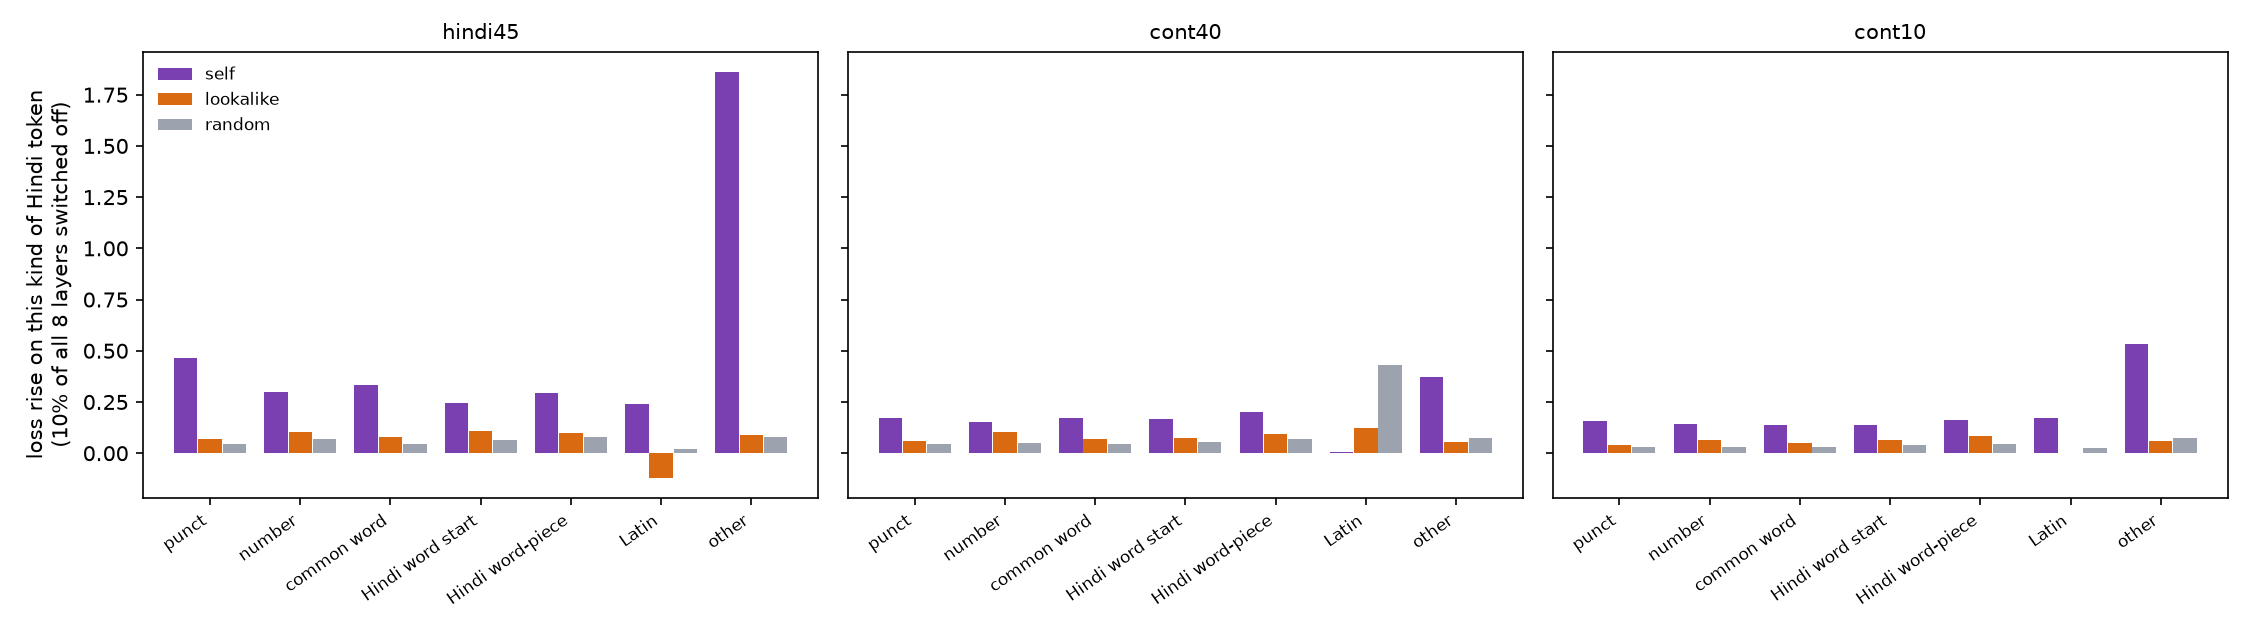

In [3]:
subprocess.run([sys.executable, "interp2_v10.py", "--summarize"])
for f in ["h4_by_kind.png"]:
    if os.path.exists(f"analysis/v10/interp2/{f}"): display(Image(f"analysis/v10/interp2/{f}"))